In [1]:
import json, math, os
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt

IMAGE_PATH =  "E:/Aidin/Universities/Amirkabir (Master)/Lessons/My-Terms/Term 4/3D Computer Vision/Assignments/HW1/Answer/Images2/3.jpg"
ANN_STAGE1_JSON = "annotations_stage1.json"
STAGE2_JSON = "stage2_result.json"
OUT_PREFIX = "stage3to5"


In [13]:
# Returns homogeneous coordinate of a 2D point
def to_h(pt):
    return np.array([float(pt[0]), float(pt[1]), 1.0], dtype=np.float64)

# Returns line coefficients from two 2D points
def line_from_points(p1, p2):
    return np.cross(to_h(p1), to_h(p2)).astype(np.float64)

# Normalizes a 2D line ax+by+c=0
def normalize_line(l):
    a,b,c = l
    n = np.hypot(a,b) + 1e-12
    return np.array([a/n, b/n, c/n], dtype=np.float64)

# Estimates vanishing point with least squares
def vp_least_squares(lines):
    if len(lines) < 2:
        return None
    L = [normalize_line(line_from_points(p1,p2)) for p1,p2 in lines]
    L = np.asarray(L, dtype=np.float64)
    A = L[:, :2]
    c = L[:, 2:3]
    v, *_ = np.linalg.lstsq(A, -c, rcond=None)
    return v.flatten()

# Estimates vanishing point with RANSAC and LS refinement
def vp_ransac(lines, iters=1000, inlier_thresh=2.5, seed=None):
    if len(lines) < 2:
        return None, []
    rng = np.random.default_rng(seed)
    L = [normalize_line(line_from_points(p1,p2)) for p1,p2 in lines]
    n = len(L)
    best_vp, best_inliers = None, []
    for _ in range(iters):
        i, j = rng.choice(n, size=2, replace=False)
        vp_h = np.cross(L[i], L[j])
        if abs(vp_h[2]) < 1e-9:
            continue
        vp = vp_h[:2] / vp_h[2]
        dists = np.abs(np.dot(L, np.r_[vp, 1.0]))
        inliers = np.where(dists < inlier_thresh)[0].tolist()
        if len(inliers) > len(best_inliers):
            best_inliers, best_vp = inliers, vp
    if best_vp is not None and len(best_inliers) >= 2:
        A = np.array([L[i][:2] for i in best_inliers], dtype=np.float64)
        c = np.array([[L[i][2]] for i in best_inliers], dtype=np.float64)
        v_ref, *_ = np.linalg.lstsq(A, -c, rcond=None)
        return v_ref.flatten(), best_inliers
    return best_vp, best_inliers

# Returns horizon line from two vanishing points
def horizon_from_vps(vx, vy):
    return np.cross(np.r_[vx,1.0], np.r_[vy,1.0])

# Clips an infinite line to image bounds
def line_clip_to_image(l, w, h):
    a,b,c = l
    pts = []
    if abs(b) > 1e-12:
        pts += [(0.0, -c/b), (w-1.0, -(a*(w-1)+c)/b)]
    if abs(a) > 1e-12:
        pts += [(-c/a, 0.0), (-(b*(h-1)+c)/a, h-1.0)]
    pts = [(x,y) for (x,y) in pts if -1 <= x <= w and -1 <= y <= h]
    if len(pts) < 2:
        return None
    best, bestd = (pts[0], pts[1]), -1
    for i in range(len(pts)):
        for j in range(i+1, len(pts)):
            d = (pts[i][0]-pts[j][0])**2 + (pts[i][1]-pts[j][1])**2
            if d > bestd:
                bestd, best = d, (pts[i], pts[j])
    pA = (int(round(best[0][0])), int(round(best[0][1])))
    pB = (int(round(best[1][0])), int(round(best[1][1])))
    return pA, pB

# Orders 4 points to TL, TR, BR, BL
def order_quad_points(pts):
    pts = np.asarray(pts, dtype=np.float64)
    c = pts.mean(axis=0)
    angles = np.arctan2(pts[:,1]-c[1], pts[:,0]-c[0])
    idx = np.argsort(angles)
    pts = pts[idx]
    s = pts.sum(axis=1)
    tl = int(np.argmin(s))
    pts = np.roll(pts, -tl, axis=0)
    return pts

# Clips homogeneous line to image bounds (alias for horizon rendering)
def clip_infinite_line_to_image(l, w, h):
    return line_clip_to_image(l, w, h)

# Projects 3D points with K, R, t
def project_points(K, R, t, Xw):
    Xw = np.asarray(Xw, dtype=np.float64).T
    Xc = R @ Xw + t.reshape(3,1)
    x  = K @ Xc
    x  = (x[:2] / x[2]).T
    return x, Xc.T

# Draws extended lines on an image
def draw_extended_lines(img, lines, color, thickness=1):
    h, w = img.shape[:2]
    for (p1, p2) in lines:
        l = normalize_line(line_from_points(p1,p2))
        seg = line_clip_to_image(l, w, h)
        if seg is not None:
            cv2.line(img, seg[0], seg[1], color, thickness, cv2.LINE_AA)

# Draws a vanishing point on an image
def draw_vp(img, vp, label, color=(0,0,255)):
    if vp is None:
        return
    x, y = int(round(vp[0])), int(round(vp[1]))
    cv2.circle(img, (x,y), 6, color, -1, cv2.LINE_AA)
    cv2.putText(img, label, (x+8, y-8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

# Draws the horizon line on an image
def draw_horizon(img, v1, v2, color=(0,0,255)):
    if (v1 is None) or (v2 is None):
        return
    l = np.cross(np.r_[v1,1.0], np.r_[v2,1.0])
    seg = clip_infinite_line_to_image(l, img.shape[1], img.shape[0])
    if seg is not None:
        cv2.line(img, seg[0], seg[1], color, 1, cv2.LINE_AA)

# Normalizes 2D points (Hartley normalization)
def normalize_points_2d(pts):
    pts = np.asarray(pts, dtype=np.float64)
    c = pts.mean(axis=0)
    d = np.sqrt(((pts - c)**2).sum(axis=1)).mean()
    s = np.sqrt(2.0) / (d + 1e-12)
    T = np.array([[s, 0, -s*c[0]],
                  [0, s, -s*c[1]],
                  [0, 0, 1]], dtype=np.float64)
    pts_h = np.c_[pts, np.ones(len(pts))]
    ptsn = (T @ pts_h.T).T
    return ptsn, T

# Estimates homography with normalized DLT
def H_from_correspondences(src_pts, dst_pts):
    srcn, Ts = normalize_points_2d(src_pts)
    dstn, Td = normalize_points_2d(dst_pts)
    A = []
    for (X,Y,_), (x,y,_) in zip(srcn, dstn):
        A.append([-X,-Y,-1, 0, 0, 0, x*X, x*Y, x])
        A.append([ 0, 0, 0,-X,-Y,-1, y*X, y*Y, y])
    A = np.asarray(A, dtype=np.float64)
    _, _, Vt = np.linalg.svd(A)
    Hn = Vt[-1].reshape(3,3)
    H = np.linalg.inv(Td) @ Hn @ Ts
    return H / H[2,2]

# Draws XYZ axes from a plane origin
def draw_axes_overlay(img_bgr, K, R, t, origin_plane=(0.5,0.5), axis_len=0.5, thickness=3):
    base = img_bgr.copy()
    Ox, Oy = origin_plane
    P0 = np.array([[Ox, Oy, 0.0],
                   [Ox+axis_len, Oy, 0.0],
                   [Ox, Oy+axis_len, 0.0],
                   [Ox, Oy, axis_len]], dtype=np.float64)
    pts2d, _ = project_points(K, R, t, P0)
    p0, px, py, pz = [tuple(map(int, np.round(p))) for p in pts2d]
    cv2.line(base, p0, px, (0, 0, 255), thickness, cv2.LINE_AA)
    cv2.line(base, p0, py, (0, 255, 0), thickness, cv2.LINE_AA)
    cv2.line(base, p0, pz, (255, 0, 0), thickness, cv2.LINE_AA)
    return base


In [3]:
# Interactive annotator for Stage 1
class Annotator:
    def __init__(self, img, out_prefix="annotations_stage1"):
        self.base = img.copy()
        self.display = img.copy()
        self.h, self.w = img.shape[:2]
        self.mode = 'quad'
        self.current_group = 'u'
        self.pending_point = None
        self.quad_points = []
        self.quad_ordered = None
        self.line_groups = {'u': [], 'v': []}
        self.vps = {}
        self.show_preview = False
        self.out_prefix = out_prefix
        self.dirty = True

    # Computes vanishing points for preview
    def compute_vps(self):
        vps = {}
        for g in ('u', 'v'):
            if len(self.line_groups[g]) >= 2:
                try:
                    vp = vp_least_squares(self.line_groups[g])
                    vps[g] = vp
                except Exception:
                    pass
        self.vps = vps
        return vps

    # Returns warning strings about far vanishing points
    def vp_quality_warnings(self):
        warnings = []
        if len(self.vps) == 0:
            return warnings
        thr = 30.0 * float(max(self.w, self.h))
        for g, v in self.vps.items():
            if v is None:
                continue
            if (abs(v[0]) > thr) or (abs(v[1]) > thr):
                warnings.append(f"VP_{g} seems very far from the frame.")
        return warnings

    # Mouse click handler
    def on_click(self, event, x, y, flags, param):
        if event != cv2.EVENT_LBUTTONDOWN:
            return
        if self.mode == 'quad':
            if len(self.quad_points) < 4:
                self.quad_points.append((float(x), float(y)))
                if len(self.quad_points) == 4:
                    self.quad_ordered = order_quad_points(self.quad_points)
        elif self.mode == 'lines':
            if self.pending_point is None:
                self.pending_point = (float(x), float(y))
            else:
                p1 = self.pending_point
                p2 = (float(x), float(y))
                self.line_groups[self.current_group].append((p1, p2))
                self.pending_point = None
        self.dirty = True

    # Keyboard handler
    def on_key(self, key):
        if key == ord('q'):
            self.mode = 'quad'
        elif key == ord('1'):
            self.mode = 'lines'; self.current_group = 'u'
        elif key == ord('2'):
            self.mode = 'lines'; self.current_group = 'v'
        elif key == ord('u'):
            self.undo()
        elif key == ord('x'):
            self.clear_current()
        elif key == ord('c'):
            self.clear_all()
        elif key == ord('h'):
            self.show_preview = not self.show_preview
            if self.show_preview:
                self.compute_vps()
        elif key == ord('p'):
            self.print_state()
        elif key == ord('s'):
            self.save_all()
        self.dirty = True

    # Undo last action
    def undo(self):
        if self.mode == 'quad':
            if self.quad_points:
                self.quad_points.pop()
                self.quad_ordered = None
        else:
            if self.pending_point is not None:
                self.pending_point = None
            elif self.line_groups[self.current_group]:
                self.line_groups[self.current_group].pop()

    # Clears current group or quad
    def clear_current(self):
        if self.mode == 'quad':
            self.quad_points = []; self.quad_ordered = None
        else:
            self.pending_point = None; self.line_groups[self.current_group] = []

    # Clears all annotations
    def clear_all(self):
        self.quad_points = []; self.quad_ordered = None
        self.pending_point = None; self.line_groups = {'u': [], 'v': []}
        self.vps = {}; self.show_preview = False

    # Redraw overlay
    def redraw(self):
        self.display = self.base.copy()
        for i, (x, y) in enumerate(self.quad_points):
            cv2.circle(self.display, (int(x), int(y)), 6, (0, 0, 255), -1)
            cv2.putText(self.display, f"{i+1}", (int(x)+6, int(y)-6),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,0,255), 1, cv2.LINE_AA)
        if self.quad_ordered is not None:
            pts = self.quad_ordered.astype(np.int32).reshape(-1, 1, 2)
            cv2.polylines(self.display, [pts], True, (255, 0, 255), 2, cv2.LINE_AA)
            labels = ["TL","TR","BR","BL"]
            for (x, y), lbl in zip(self.quad_ordered, labels):
                cv2.circle(self.display, (int(x), int(y)), 6, (255, 0, 255), 1)
                cv2.putText(self.display, lbl, (int(x)+6, int(y)-6),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255,0,255), 2, cv2.LINE_AA)
        colors = {'u': (0, 200, 0), 'v': (0, 165, 255)}
        for g in ('u','v'):
            for (p1, p2) in self.line_groups[g]:
                cv2.circle(self.display, (int(p1[0]), int(p1[1])), 5, colors[g], -1)
                cv2.circle(self.display, (int(p2[0]), int(p2[1])), 5, colors[g], -1)
                cv2.line(self.display, (int(p1[0]), int(p1[1])),
                         (int(p2[0]), int(p2[1])), (255, 0, 0), 2, cv2.LINE_AA)
        if self.pending_point is not None:
            cv2.circle(self.display, (int(self.pending_point[0]), int(self.pending_point[1])), 6, (255,255,0), -1)
        if self.show_preview:
            if len(self.vps) == 0:
                self.compute_vps()
            for g, vp in self.vps.items():
                if vp is None:
                    continue
                vx, vy = int(round(vp[0])), int(round(vp[1]))
                if -10000 <= vx <= self.w + 10000 and -10000 <= vy <= self.h + 10000:
                    cv2.circle(self.display, (vx, vy), 6, (0,0,255), -1)
                    cv2.putText(self.display, f"VP_{g}", (vx+8, vy-8),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,0,255), 2, cv2.LINE_AA)
            if set(self.vps.keys()) == {'u','v'}:
                l = horizon_from_vps(self.vps['u'], self.vps['v'])
                seg = line_clip_to_image(l, self.w, self.h)
                if seg is not None:
                    cv2.line(self.display, seg[0], seg[1], (0,0,255), 1, cv2.LINE_AA)
        self.dirty = False

    # Prints current state to console
    def print_state(self):
        print("\n--- Current Coordinates ---")
        print("Quadrilateral raw:", np.array(self.quad_points, dtype=np.float64))
        if self.quad_ordered is not None:
            print("Quadrilateral ordered:", self.quad_ordered)
        def _fmt(lines): return [[list(map(float,p1)), list(map(float,p2))] for p1,p2 in lines]
        print("Lines [u]:", len(self.line_groups['u']))
        print(np.array(_fmt(self.line_groups['u']), dtype=object))
        print("Lines [v]:", len(self.line_groups['v']))
        print(np.array(_fmt(self.line_groups['v']), dtype=object))
        self.compute_vps()
        for g in ('u','v'):
            if g in self.vps: print(f"VP_{g}:", self.vps[g])
        for w in self.vp_quality_warnings():
            print(w)

    # Saves overlay image and JSON to disk
    def save_all(self):
        self.compute_vps()
        overlay_path = f"{self.out_prefix}_overlay.png"
        cv2.imwrite(overlay_path, self.display)
        data = {
            "image_size": {"width": int(self.w), "height": int(self.h)},
            "quad_raw": np.asarray(self.quad_points, dtype=float).tolist(),
            "quad_ordered": (None if self.quad_ordered is None else self.quad_ordered.astype(float).tolist()),
            "lines_u": [[list(map(float,p1)), list(map(float,p2))] for p1,p2 in self.line_groups['u']],
            "lines_v": [[list(map(float,p1)), list(map(float,p2))] for p1,p2 in self.line_groups['v']],
            "vps_preview": {k: [float(v[0]), float(v[1])] for k, v in self.vps.items()},
        }
        with open(f"{self.out_prefix}.json", "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False, indent=2)
        print("Saved:", overlay_path, "and", f"{self.out_prefix}.json")

# Runs Stage 1 in a notebook
def run_stage1_notebook(image_path, out_prefix="annotations_stage1"):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Image not found: {image_path}")
    ann = Annotator(img, out_prefix=out_prefix)
    win = "Annotation - Stage 1"
    cv2.namedWindow(win, cv2.WINDOW_AUTOSIZE)
    cv2.setMouseCallback(win, lambda e, x, y, f, p: ann.on_click(e, x, y, f, p))
    print("q=quad, 1=u, 2=v, u=undo, x=clear current, c=clear all, h=preview, p=print, s=save, Esc=exit")
    while True:
        if ann.dirty:
            ann.redraw()
        cv2.imshow(win, ann.display)
        key = cv2.waitKey(20) & 0xFF
        if key == 27:
            ann.save_all()
            break
        elif key != 255:
            ann.on_key(key)
    cv2.destroyAllWindows()


In [14]:
run_stage1_notebook(IMAGE_PATH, "annotations_stage1")


q=quad, 1=u, 2=v, u=undo, x=clear current, c=clear all, h=preview, p=print, s=save, Esc=exit
Saved: annotations_stage1_overlay.png and annotations_stage1.json


In [5]:
# Runs Stage 2: estimates VPs/horizon/intrinsics, draws principal point, and saves homogeneous VPs
def run_stage2_notebook(image_path, ann_json_path, out_prefix="stage2_result",
                        use_ransac=True, ransac_thresh=2.5, show=True, min_lines=4):
    img = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Image not found: {image_path}")
    h, w = img.shape[:2]

    with open(ann_json_path, "r", encoding="utf-8") as f:
        ann = json.load(f)
    lines_u = [(tuple(p1), tuple(p2)) for p1, p2 in ann.get("lines_u", [])]
    lines_v = [(tuple(p1), tuple(p2)) for p1, p2 in ann.get("lines_v", [])]

    if len(lines_u) < min_lines or len(lines_v) < min_lines:
        raise ValueError(f"At least {min_lines} lines per group are required (got u={len(lines_u)}, v={len(lines_v)}).")

    if use_ransac:
        vu, in_u = vp_ransac(lines_u, iters=1000, inlier_thresh=ransac_thresh)
        vv, in_v = vp_ransac(lines_v, iters=1000, inlier_thresh=ransac_thresh)
    else:
        vu, vv = vp_least_squares(lines_u), vp_least_squares(lines_v)
        in_u = list(range(len(lines_u))); in_v = list(range(len(lines_v)))

    c = np.array([w/2.0, h/2.0], dtype=np.float64)
    f2 = - float(np.dot(vu - c, vv - c))
    if not np.isfinite(f2) or f2 <= 0:
        f = math.nan
        warn = [f"invalid f^2 (value={f2})"]
    else:
        f = float(np.sqrt(f2))
        warn = []

    K = np.array([[f, 0.0, c[0]],
                  [0.0, f, c[1]],
                  [0.0, 0.0, 1.0]], dtype=np.float64)

    overlay = img.copy()
    draw_extended_lines(overlay, [lines_u[i] for i in in_u], color=(0,200,0), thickness=1)
    draw_extended_lines(overlay, [lines_v[i] for i in in_v], color=(0,165,255), thickness=1)
    draw_vp(overlay, vu, "VP_u", color=(0,0,255))
    draw_vp(overlay, vv, "VP_v", color=(0,0,255))
    draw_horizon(overlay, vu, vv, color=(0,0,255))
    cv2.drawMarker(overlay, (int(round(c[0])), int(round(c[1]))), (255,255,255),
                   markerType=cv2.MARKER_CROSS, markerSize=14, thickness=2)

    out_img = f"{out_prefix}_overlay.png"
    cv2.imwrite(out_img, overlay)

    out_json = {
        "image_size": {"width": int(w), "height": int(h)},
        "principal_point": {"cx": float(c[0]), "cy": float(c[1])},
        "VP_u": None if vu is None else {"x": float(vu[0]), "y": float(vu[1])},
        "VP_v": None if vv is None else {"x": float(vv[0]), "y": float(vv[1])},
        "VP_u_h": None if vu is None else [float(vu[0]), float(vu[1]), 1.0],
        "VP_v_h": None if vv is None else [float(vv[0]), float(vv[1]), 1.0],
        "f": None if not np.isfinite(f) else float(f),
        "K": None if not np.isfinite(f) else np.asarray(K, dtype=float).tolist(),
        "inliers_u": len(in_u),
        "inliers_v": len(in_v),
        "warnings": warn
    }
    with open(f"{out_prefix}.json", "w", encoding="utf-8") as fjs:
        json.dump(out_json, fjs, ensure_ascii=False, indent=2)

    print("--- Stage 2 ---")
    print("VP_u:", None if vu is None else np.round(vu,2))
    print("VP_u (homog):", None if vu is None else [round(float(vu[0]),3), round(float(vu[1]),3), 1.0])
    print("VP_v:", None if vv is None else np.round(vv,2))
    print("VP_v (homog):", None if vv is None else [round(float(vv[0]),3), round(float(vv[1]),3), 1.0])
    print("Principal point (cx,cy):", (round(float(c[0]),2), round(float(c[1]),2)))
    print("f:", None if not np.isfinite(f) else round(f,3))
    print("Saved:", out_img, f"{out_prefix}.json")
    if warn:
        for wmsg in warn:
            print("Warning:", wmsg)

    if show:
        plt.figure(figsize=(10,6))
        plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        plt.title("Stage 2: VPs, Horizon, Principal Point, Intrinsics")
        plt.axis('off'); plt.show()


--- Stage 2 ---
VP_u: [-308517.32     945.2 ]
VP_u (homog): [-308517.319, 945.198, 1.0]
VP_v: [ 387.68 -207.75]
VP_v (homog): [387.679, -207.754, 1.0]
Principal point (cx,cy): (370.0, 277.5)
f: 2405.176
Saved: stage2_result_overlay.png stage2_result.json


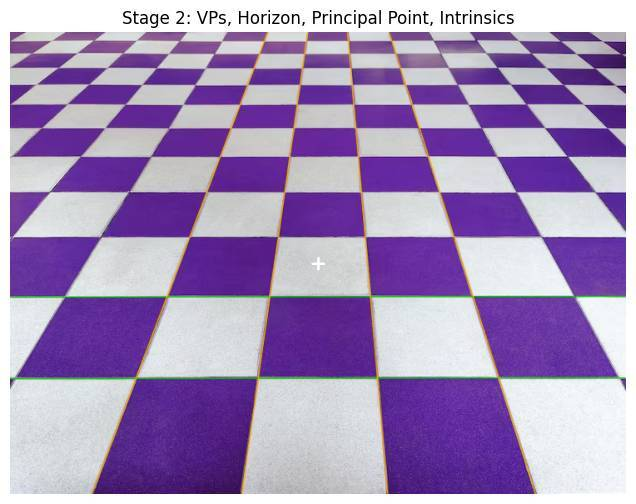

In [6]:
run_stage2_notebook(IMAGE_PATH, ANN_STAGE1_JSON, out_prefix="stage2_result",
                    use_ransac=True, ransac_thresh=2.5, show=True)


--- Stage 3 ---
Mean corner reprojection error: 0.0
Saved rectified image: stage3to5_stage3_rectified.png


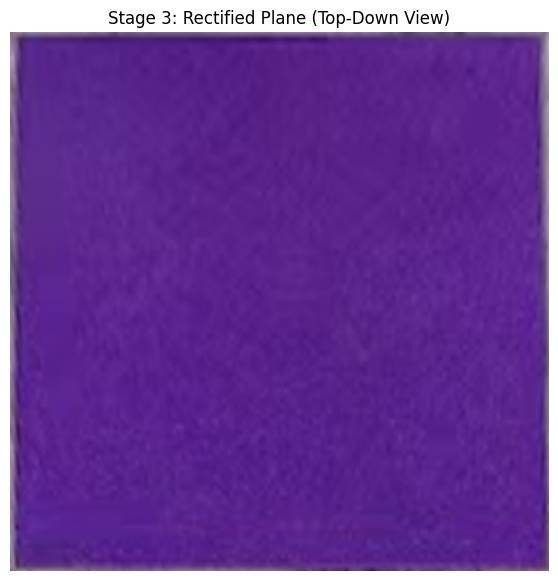

In [7]:
# Runs Stage 3: compute planar H and reprojection error
def run_stage3_compute_H(ann_stage1_json, stage2_json, out_prefix="stage3to5"):
    with open(ann_stage1_json, "r", encoding="utf-8") as f:
        ann1 = json.load(f)
    quad = np.array(ann1.get("quad_ordered") or ann1.get("quad_raw"), dtype=np.float64)
    assert quad.shape == (4,2)
    unit_square = np.array([[0.0,0.0],[1.0,0.0],[1.0,1.0],[0.0,1.0]], dtype=np.float64)
    H = H_from_correspondences(unit_square, quad)
    reproj = []
    for XY, x_img in zip(unit_square, quad):
        Xh = np.array([XY[0], XY[1], 1.0])
        xp = (H @ Xh); xp = xp[:2] / xp[2]
        reproj.append(np.linalg.norm(xp - x_img))
    mean_err = float(np.mean(reproj))
    np.savez(f"{out_prefix}_stage3.npz", H=H, quad=quad, unit_square=unit_square, mean_err=mean_err)
    print("--- Stage 3 ---")
    print("Mean corner reprojection error:", round(mean_err,3))
    return H, quad, unit_square

H, quad, unit_square = run_stage3_compute_H(ANN_STAGE1_JSON, STAGE2_JSON, OUT_PREFIX)

# -----------------------------------------------------------------
# --- کد جدید: این تابع را اینجا اضافه کنید ---
# -----------------------------------------------------------------

# Runs Stage 3 (Part 2): create and save the rectified top-down image
def run_stage3_warp_image(image_path, quad, out_prefix="stage3to5", out_size=(500, 500)):
    """
    Warps the original image to create a top-down view of the selected quad.
    """
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Image not found at {image_path}")

    W_out, H_out = out_size
    
    # Define the destination points for the rectangle (top-left, top-right, bottom-right, bottom-left)
    dst_pts = np.array([
        [0, 0],
        [W_out - 1, 0],
        [W_out - 1, H_out - 1],
        [0, H_out - 1]
    ], dtype=np.float32)

    # Get the source points (must be in float32 for getPerspectiveTransform)
    src_pts = np.asarray(quad, dtype=np.float32)

    # Compute the perspective transformation matrix M (Image -> TopDown)
    M = cv2.getPerspectiveTransform(src_pts, dst_pts)
    
    # Apply the warp
    warped = cv2.warpPerspective(img, M, (W_out, H_out))
    
    # Save and show the image
    out_path = f"{out_prefix}_stage3_rectified.png"
    cv2.imwrite(out_path, warped)
    print(f"Saved rectified image: {out_path}")

    plt.figure(figsize=(7, 7)) # Show as a square
    plt.imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
    plt.title("Stage 3: Rectified Plane (Top-Down View)")
    plt.axis('off')
    plt.show()
    
    return warped

# --- فراخوانی تابع جدید ---
img_rectified = run_stage3_warp_image(IMAGE_PATH, quad, OUT_PREFIX)

# -----------------------------------------------------------------
# --- ادامه کد شما از اینجا شروع می شود ---


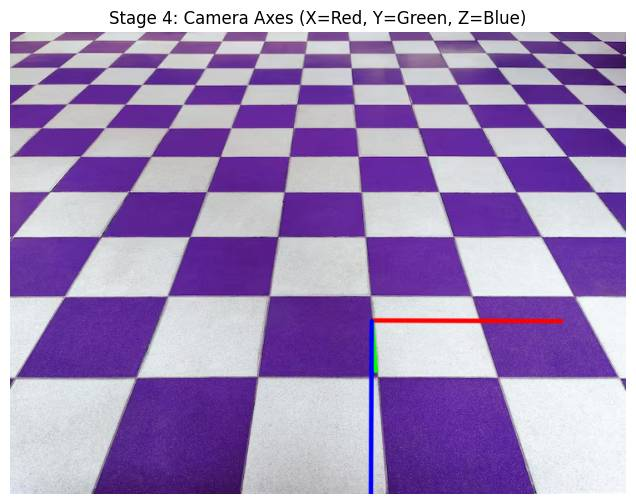

In [8]:
# Runs Stage 4: recover R,t and draw axes
def run_stage4_pose_axes(image_path, stage2_json, H, out_prefix="stage3to5"):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    with open(stage2_json, "r", encoding="utf-8") as f:
        ann2 = json.load(f)
    K = np.array(ann2["K"], dtype=np.float64)
    H_tilde = np.linalg.inv(K) @ H
    h1, h2, h3 = H_tilde[:,0], H_tilde[:,1], H_tilde[:,2]
    lam = 0.5 * (np.linalg.norm(h1) + np.linalg.norm(h2))
    if lam < 0: lam = -lam
    r1 = h1 / lam; r2 = h2 / lam; r3 = np.cross(r1, r2)
    R_hat = np.column_stack([r1, r2, r3])
    U, _, Vt = np.linalg.svd(R_hat)
    R = U @ Vt
    if np.linalg.det(R) < 0:
        U[:,-1] *= -1; R = U @ Vt
    t = h3 / lam
    test_pts = np.array([[0.5,0.5,0.0],[0.2,0.2,0.0],[0.8,0.2,0.0],[0.5,0.8,0.0]], dtype=np.float64)
    _, Xc = project_points(K, R, t, test_pts)
    if np.mean(Xc[:,2]) < 0:
        R[:,2] *= -1; t *= -1
    overlay_axes = draw_axes_overlay(img, K, R, t, origin_plane=(0.5,0.5), axis_len=0.9, thickness=4)
    plt.figure(figsize=(10,6))
    plt.imshow(cv2.cvtColor(overlay_axes, cv2.COLOR_BGR2RGB))
    plt.title("Stage 4: Camera Axes (X=Red, Y=Green, Z=Blue)")
    plt.axis('off'); plt.show()
    cv2.imwrite(f"{out_prefix}_stage4_axes.png", overlay_axes)
    np.savez(f"{out_prefix}_stage4.npz", R=R, t=t, K=K, H=H)
    return R, t, K, overlay_axes

R, t, K, overlay_axes = run_stage4_pose_axes(IMAGE_PATH, STAGE2_JSON, H, OUT_PREFIX)


In [12]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interactive

def face_normal_cam(Xc, i0, i1, i2):
    v0, v1, v2 = Xc[i0], Xc[i1], Xc[i2]
    n = np.cross(v1 - v0, v2 - v0)
    d = np.linalg.norm(n) + 1e-12
    return n / d

def lambert_brightness(n_hat, l_hat, ambient=0.2):
    return float(max(ambient, float(np.dot(n_hat, -l_hat))))


# Interactive function to adjust margin, size, and offsets
def interactive_run_stage5_cube_shaded(image_path, K, R, t, out_prefix="stage3to5",
                                       margin=0.03, size=0.94, 
                                       offset_x=0.0, offset_y=0.0, offset_z=0.0,
                                       light_dir=(-0.5, -0.5, -1.0), ambient=0.2):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    base_min = margin; base_max = margin + size
    base = np.array([[base_min, base_min, 0.0],
                     [base_max, base_min, 0.0],
                     [base_max, base_max, 0.0],
                     [base_min, base_max, 0.0]], dtype=np.float64)
    top = base.copy(); top[:,2] = size
    V = np.vstack([base, top])
    
    # Apply user-defined offset (shift in plane coordinates)
    offset = np.array([offset_x, offset_y, offset_z])
    V += offset
    
    edges = [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),(0,4),(1,5),(2,6),(3,7)]
    faces = [(0,3,2,1),(4,5,6,7),(0,1,5,4),(1,2,6,5),(2,3,7,6),(3,0,4,7)]
    
    # Project cube vertices
    pts2d, Xc = project_points(K, R, t, V)
    
    # --- Wireframe (Black edges) ---
    wire = img.copy()
    for (i,j) in edges:
        p1 = tuple(map(int, np.round(pts2d[i])))
        p2 = tuple(map(int, np.round(pts2d[j])))
        cv2.line(wire, p1, p2, (0, 0, 0), 3, cv2.LINE_AA)  # Black wireframe edges
    cv2.imwrite(f"{out_prefix}_stage5_wire.png", wire)
    
    # --- Shading (Red body color) ---
    l_hat = np.array(light_dir, dtype=np.float64)
    l_hat = l_hat / (np.linalg.norm(l_hat) + 1e-12)
    face_depths = []
    for f in faces:
        z_mean = float(np.mean(Xc[list(f), 2]))
        n_hat = face_normal_cam(Xc, f[0], f[1], f[2])
        b = lambert_brightness(n_hat, l_hat, ambient=ambient)
        face_depths.append((z_mean, f, b, n_hat))
    face_depths.sort(reverse=True)  # back-to-front
    
    shaded = img.copy()
    base_color = np.array([0, 0, 2550], dtype=np.float64)  # Red body color
    face_stats = []
    for z_mean, f, b, n_hat in face_depths:
        poly = np.array([pts2d[i] for i in f], dtype=np.int32).reshape(-1,1,2)
        col = np.clip(base_color * b, 0, 255).astype(np.uint8)
        cv2.fillPoly(shaded, [poly], color=tuple(int(x) for x in col))  # Red faces
        cv2.polylines(shaded, [poly], isClosed=True, color=(0, 0, 0), thickness=3, lineType=cv2.LINE_AA)  # Black boundary lines
        face_stats.append({
            "face": tuple(f),
            "normal": [float(n_hat[0]), float(n_hat[1]), float(n_hat[2])],
            "brightness": float(b)
        })
    
    # Save and display
    plt.figure(figsize=(10,6))
    plt.imshow(cv2.cvtColor(shaded, cv2.COLOR_BGR2RGB))
    plt.title("Stage 5: Large Shaded Cube (Shifted)"); plt.axis('off'); plt.show()
    cv2.imwrite(f"{out_prefix}_stage5_shaded.png", shaded)
    
    print("--- Face normals and brightness ---")
    for i, s in enumerate(face_stats):
        print(f"Face {i+1} {s['face']} normal={np.round(s['normal'],4)} brightness={round(s['brightness'],4)}")
    
    return wire, shaded, face_stats

# Now, create widgets to control the parameters:

# Define the widgets
margin_slider = widgets.FloatSlider(value=0.03, min=0.0, max=0.5, step=0.01, description="Margin:")
size_slider = widgets.FloatSlider(value=0.94, min=0.5, max=1.0, step=0.01, description="Size:")
offset_x_slider = widgets.FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, description="Offset X:")
offset_y_slider = widgets.FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, description="Offset Y:")
offset_z_slider = widgets.FloatSlider(value=0.0, min=-2.0, max=2.0, step=0.1, description="Offset Z:")

# Link the function to the widgets
interactive_plot = interactive(interactive_run_stage5_cube_shaded,
                               image_path=widgets.fixed(IMAGE_PATH),
                               K=widgets.fixed(K),
                               R=widgets.fixed(R),
                               t=widgets.fixed(t),
                               out_prefix=widgets.fixed("stage3to5"),
                               margin=margin_slider,
                               size=size_slider,
                               offset_x=offset_x_slider,
                               offset_y=offset_y_slider,
                               offset_z=offset_z_slider,
                               light_dir=widgets.fixed((-0.5, -0.5, -1.0)),
                               ambient=widgets.fixed(0.2))

# Display the interactive widget
display(interactive_plot)


interactive(children=(FloatSlider(value=0.03, description='Margin:', max=0.5, step=0.01), FloatSlider(value=0.…